# Part 2 of DQN: Implementing DQN from sratch using Deep Mind papper

In [ ]:

from environment import WumpusWorldEnvironment
import pygame
from pygame import gfxdraw
from collections import deque
import gymnasium as gym
from gymnasium import spaces
import numpy as np
import matplotlib.pyplot as plt
import random
import torch
import torch.nn as nn
#we use this library to apply operations sch as one-hot encoding to the tensore
import torch.nn.functional as F

### For simplicity we will use the interger (0-35) vector to represent the environemnt to keep it concise. The input to the nueral network is a vector of length 36 each hidden layer has 64 nuerons and the output has 4 units. No need to use the CNN unless we use images, Future iterations of the project can include multiple.

In [69]:
#First we will provide base hyperparamters(these can be altered for hyperatamter tuning)
BATCH_SIZE = 64
REPLAY_BUFFER_SIZE = 100000
GAMMA = 0.99
LEARNING_RATE = 0.01
EPSILON_START = 1.0
EPSILON_END = 0.005
EPSILON_DECAY_STEPS = 180
MAX_EPISODES = 1000
TARGET_UPDATE = 321
MAX_STEPS = 100
#use macbook gpu.
device = torch.device("mps")


In [30]:
#Defining the Q_network structure. We are using the (0-35) vector represneation
class Q_Network(nn.Module):
    """Maps one-hot gird posiiton to Q_Values for the discrete action set:"""
    def __init__(self):
        super().__init__()
        self.neural_network_vector2  = nn.Sequential(
        nn.Linear(36,64),
        nn.ReLU(),
        nn.Linear(64,4)
    )

    #Forward propogation
    def forward(self,state):
        return self.neural_network_vector2(state)

In [31]:
"""Converting the envionements integer psoition to a tensor"""
def encode_state(state):
    state_tensor = torch.tensor(int(state),dtype=torch.long,device=device)
    return F.one_hot(state_tensor,num_classes=36).float().unsqueeze(0)


In [32]:
"""INITILAIZING THE REPLAY MEMORY BUFFER WITh entires: (s,a,r,s',termination_flags)"""
#we use a queue to represent the replay buffer so the first episode we saw gets dequeed first in constant time.,
replay_memory = deque(maxlen=REPLAY_BUFFER_SIZE)
#initaize the live q_network and the target q_netwrk used to compute MSE
online_network = Q_Network().to(device)
target_network = Q_Network().to(device)
target_network.load_state_dict(online_network.state_dict())
target_network.eval()

#initilaize the loss function
optimizer = torch.optim.Adam(online_network.parameters(),lr=LEARNING_RATE)
loss_function = nn.MSELoss()

#initlaize the wumpus environemnt and initial values
environment = WumpusWorldEnvironment(observation_type='integer', action_type='discrete')
env_steps = 0
optimizer_steps = 0
results = []
losses = []
training_steps = []
epsilon_hist = []


In [33]:
"""Picking an action given a state via epislon greedy and returning the assoicate Q_value via the bellman equation"""
def pick_action(state,epsilon):
    #we choose to explore
    if random.random() < epsilon:
        return environment.action_space.sample()

    #we choose to take the greeyd action(action with the highest q_value)
    with torch.no_grad():
        #run the online nueral network to get q_values
        q_values = online_network(encode_state(state))
    return int(q_values.argmax(dim=1).item())

In [34]:
"""Now we implemnt the traning/Q_network update loop for the DQN algorithm. following the following steps
    1. Sample mini Batch


"""
def train():
    #Sample a mini_batch and make a gradient descent update
    global optimizer_steps
    if len(replay_memory) < BATCH_SIZE:
        return None

    mini_batch = random.sample(replay_memory,BATCH_SIZE)
    states,actions,rewards,next_states,termination = zip(*mini_batch)
    #one-hot encode the states and convert actions,and rweads to tensors
    states = F.one_hot(torch.tensor(states, dtype=torch.long,device=device), num_classes=36).float()
    actions = torch.tensor(actions,dtype=torch.long,device=device).unsqueeze(1)
    rewards = torch.tensor(rewards,dtype=torch.float32,device=device)
    next_states = F.one_hot(torch.tensor(next_states, dtype=torch.long,device=device), num_classes=36).float()
    termination = torch.tensor(termination,dtype=torch.long,device=device)

    #Get the predicted  values from the live Q network. Q_online(s,a)
    predictions = online_network(states).gather(1,actions).squeeze(1)
    #update the target network
    with torch.no_grad():
        next_q_values = target_network(next_states).max(dim=1).values
        targets = rewards + GAMMA * (1.0 - termination) * next_q_values

    #compute the loss, take rthe gradient and perform grdient descent/backpropagation
    loss = loss_function(predictions,targets)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    optimizer_steps+=1
    if optimizer_steps % TARGET_UPDATE == 0:
        target_network.load_state_dict(online_network.state_dict())

    return loss.item()





In [35]:
"""Now we finnally combine all the previous steps to conduct the DQN algorihtm for the environment reading the values produced."""
for episode in range(MAX_EPISODES):
    state,info = environment.reset()
    episode_return = 0.0

    for t in range(environment.max_timesteps):
        #to slighlt change epislon as training goes on so we are not stuck exploring
        epsilon = EPSILON_END + (EPSILON_START - EPSILON_END) * (max(0, EPSILON_DECAY_STEPS - env_steps) / EPSILON_DECAY_STEPS)
        training_steps.append(env_steps)
        epsilon_hist.append(epsilon)
        action = pick_action(state,epsilon)
        next_state,reward,terminated,truncated,info = environment.step(action)
        done = terminated or truncated
        replay_memory.append((int(state),int(action),float(reward),int(next_state),done))

        loss = train()
        if loss is not None:
            losses.append(loss)

        state = next_state
        episode_return += reward
        env_steps += 1
        #if we have terminated/ hit the the terminated state we are done
        if done:
            break

        results.append(episode_return)
        losses.append(float(np.mean(losses)) if losses else np.nan)
    

        


            


In [36]:
"""plotting the rewardas"""
def plot_rewards(results,losses,training_steps,epsilon_hist):
    fig,axes = plt.subplots(1,3,figsize=(16,4))
    axes[0].plot(results)
    axes[0].set(title="Total reward per episode", xlabel="Episode", ylabel="Reward")
    axes[1].plot(losses)
    axes[1].set(title="Total loss per episode", xlabel="Episode", ylabel="Mean loss")
    axes[2].plot(training_steps,epsilon_hist)
    axes[2].set(title="Epsilon decay", xlabel="Environment step", ylabel="Epsilon")

    plt.tight_layout()
    plt.show()

In [37]:
print(len(results), len(losses), len(training_steps), len(epsilon_hist))

130015 260967 131015 131015


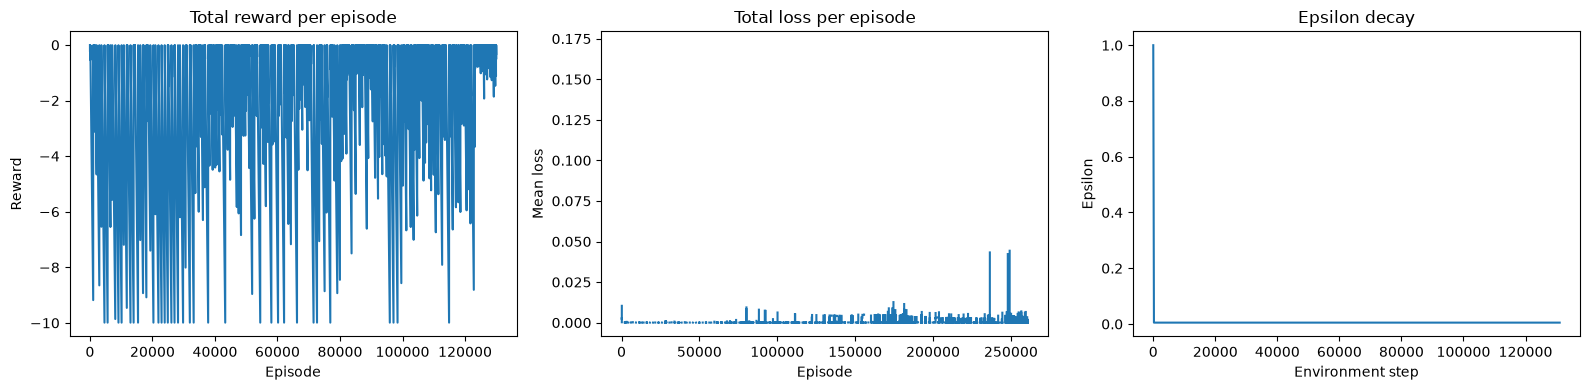

In [38]:
plot_rewards(results,losses,training_steps,epsilon_hist)

Episode # 1: reward = -10.00
Episode # 2: reward = -10.00
Episode # 3: reward = -10.00
Episode # 4: reward = -10.00
Episode # 5: reward = -10.00
Episode # 6: reward = -10.00
Episode # 7: reward = -10.00
Episode # 8: reward = -10.00
Episode # 9: reward = -10.00
Episode # 10: reward = -10.00


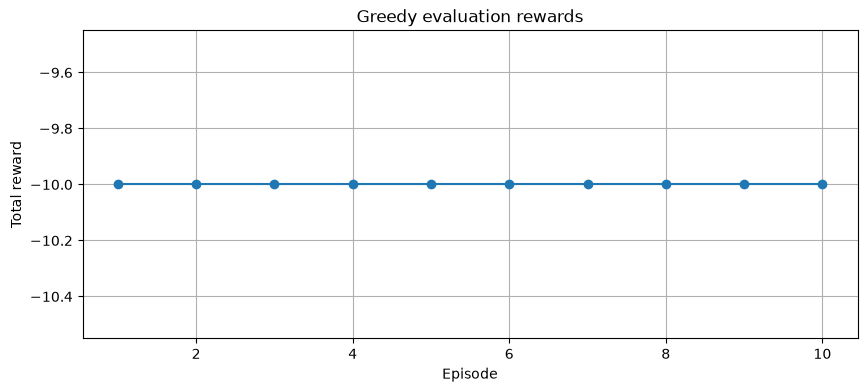

In [74]:
"""Function to stimulate taking greedy actions and evalauting them for each of the enviornemnts."""
def greedy_action(state,q_network):
    #Choose highest Q-action without exploring
    device = next(q_network.parameters()).device
    state_tensor = torch.tensor([int(state)], dtype=torch.long, device=device)
    state_vector = F.one_hot(state_tensor, num_classes=36).float()
    with torch.no_grad():
        return int(q_network(state_vector).argmax(dim=1).item())

def eval_greedy(environment,q_network,episodes_count=10,plot=True):
    """Run greedy evalution eprisodes and olot their total rewrads: save plots to report"""
    training = q_network.training
    q_network.eval()
    network_rewards = []

    #run each epsidoe and strictly take the greedy action and record the results
    try:
        for episode in range(episodes_count):
            state,anything = environment.reset()
            total_reward = 0.0
            for t in range(environment.max_timesteps):
                action = greedy_action(state,q_network)
                next_state,reward,terminated,truncated,info = environment.step(action)
                total_reward+=float(reward)
                state = next_state

                if terminated or truncated:
                    break

            network_rewards.append(total_reward)
            print(f"Episode # {episode + 1}: reward = {total_reward:.2f}")
    finally:
        q_network.train(training)

    if plot:
        plt.figure(figsize=(10,4))
        plt.plot(range(1,episodes_count+1), network_rewards, marker='o')
        plt.xlabel("Episode")
        plt.ylabel("Total reward")
        plt.title("Greedy evaluation rewards")
        plt.grid(True)
        plt.show()
    return network_rewards

evaluation_rewards = eval_greedy(environment,online_network,10)

Start: position=[0, 0]


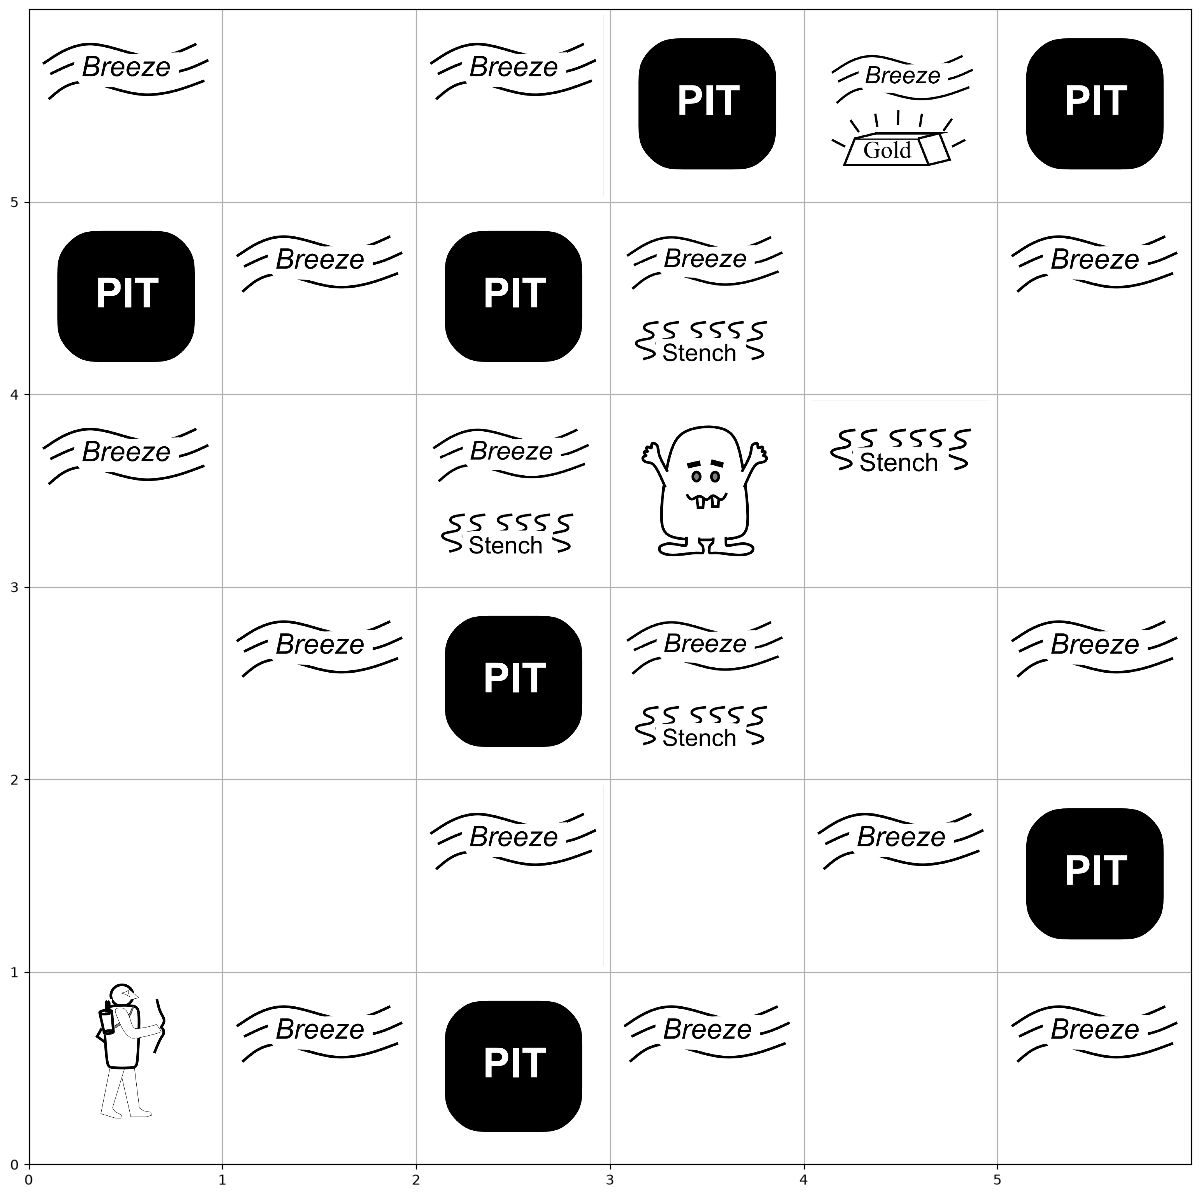

step 1: action=2,
position=[0, 1], rewards=-0.01


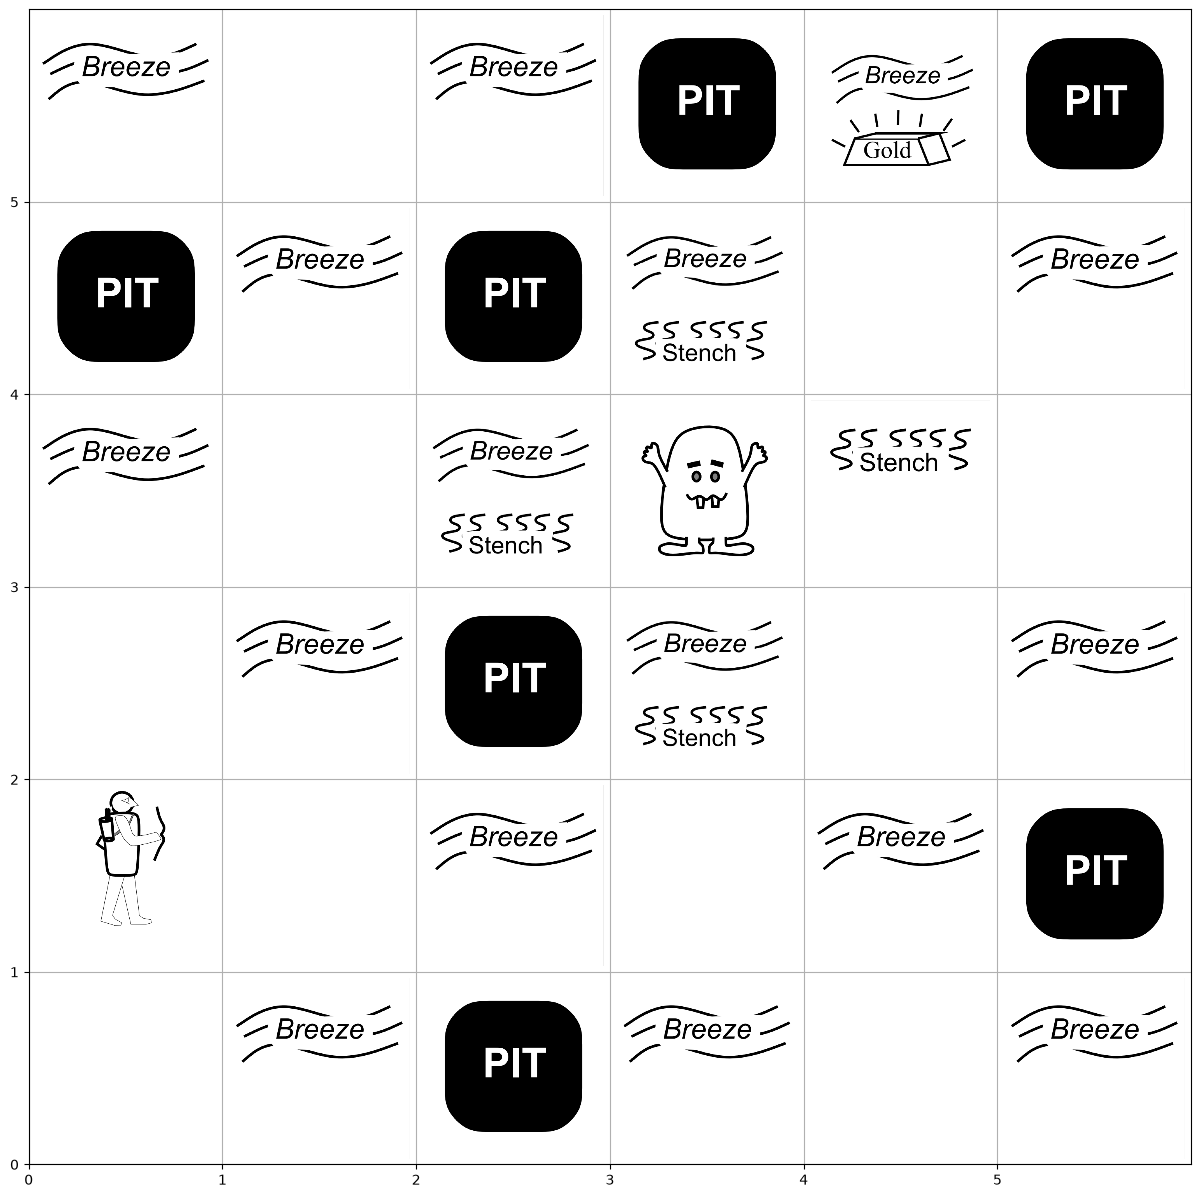

step 2: action=0,
position=[1, 1], rewards=-0.01


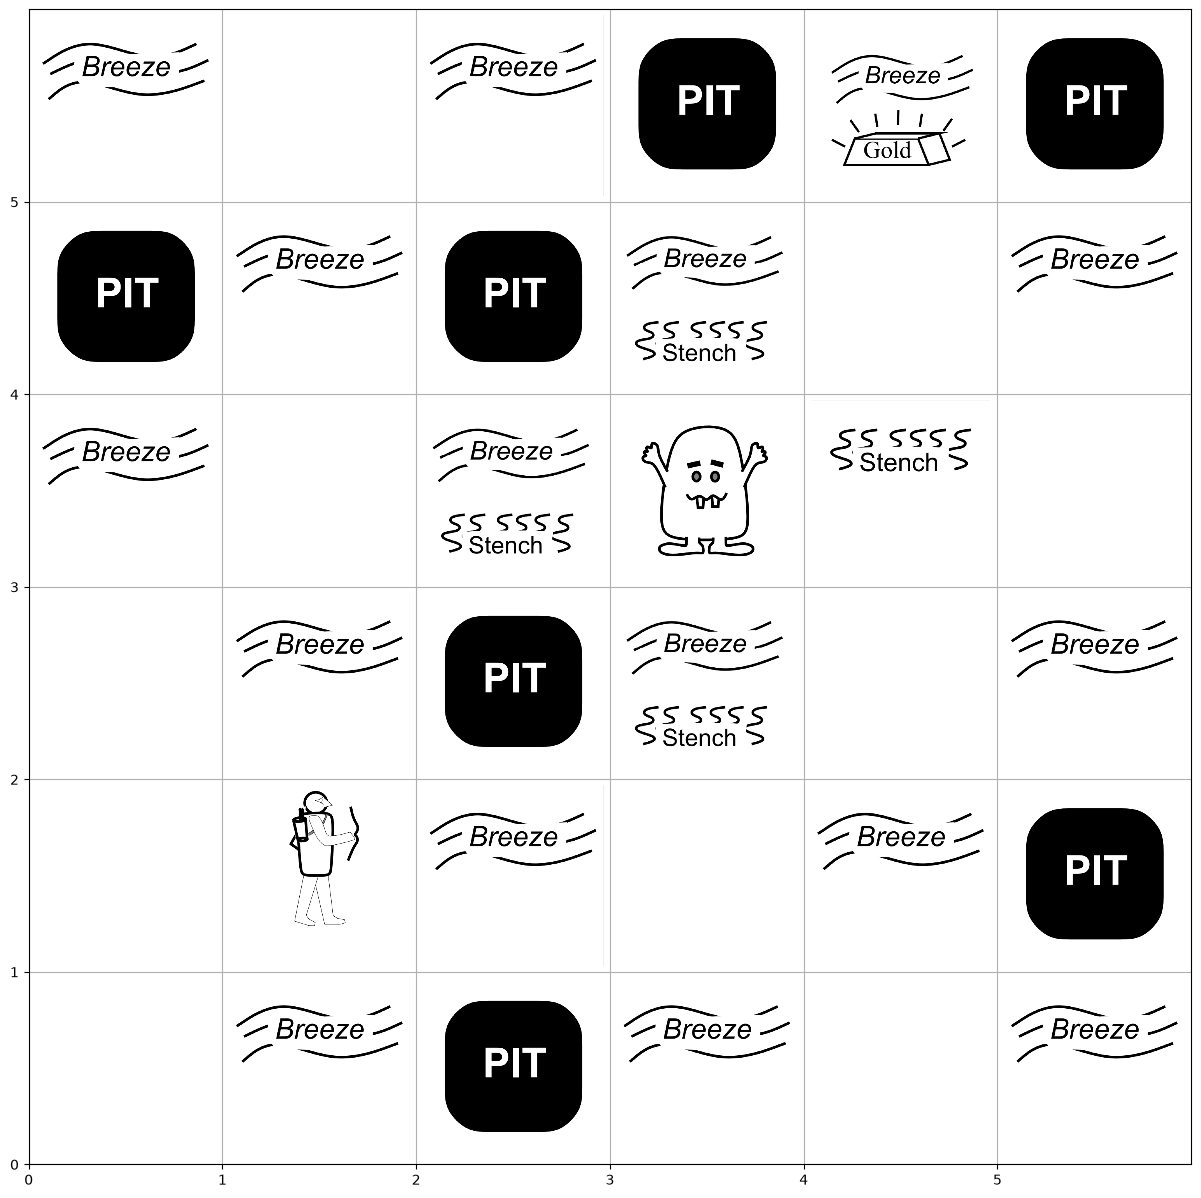

step 3: action=0,
position=[2, 1], rewards=-0.01


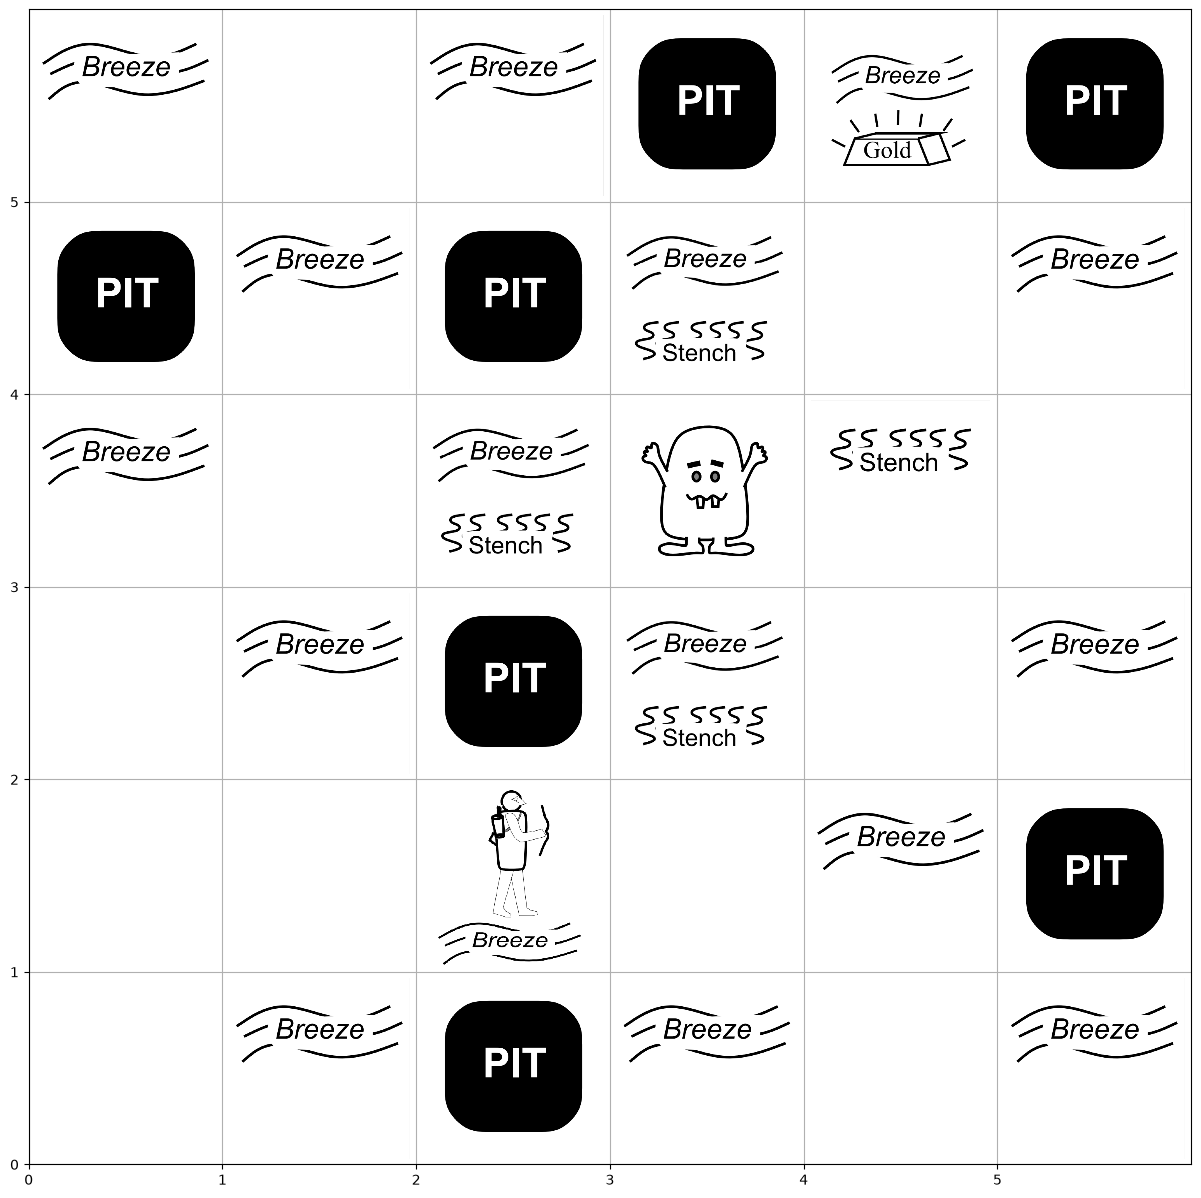

step 4: action=0,
position=[3, 1], rewards=-0.01


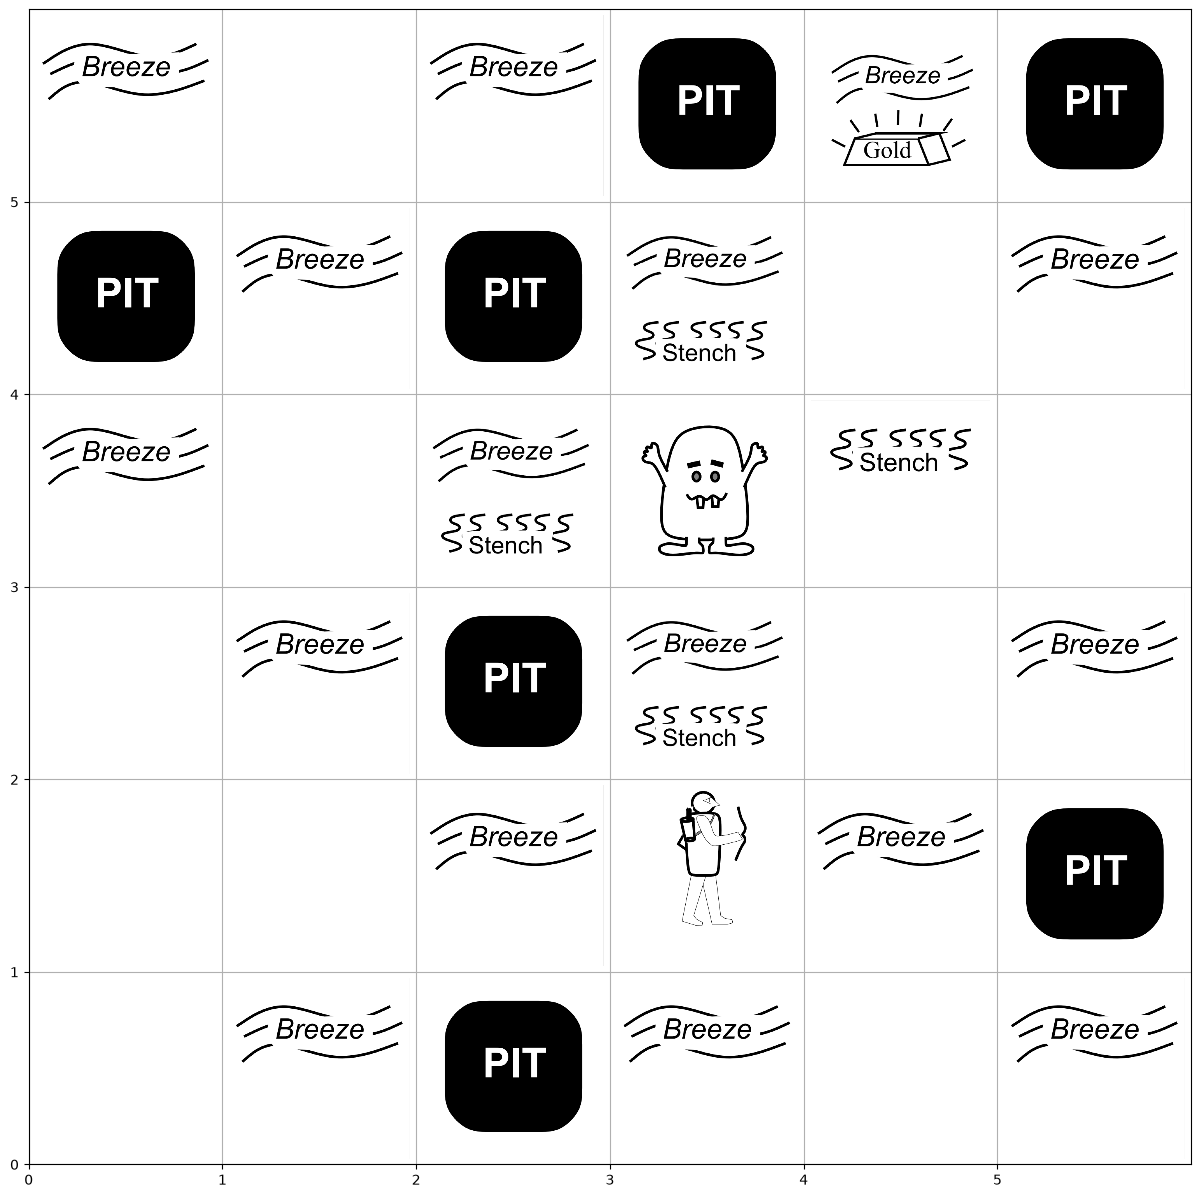

step 5: action=2,
position=[3, 2], rewards=-0.01


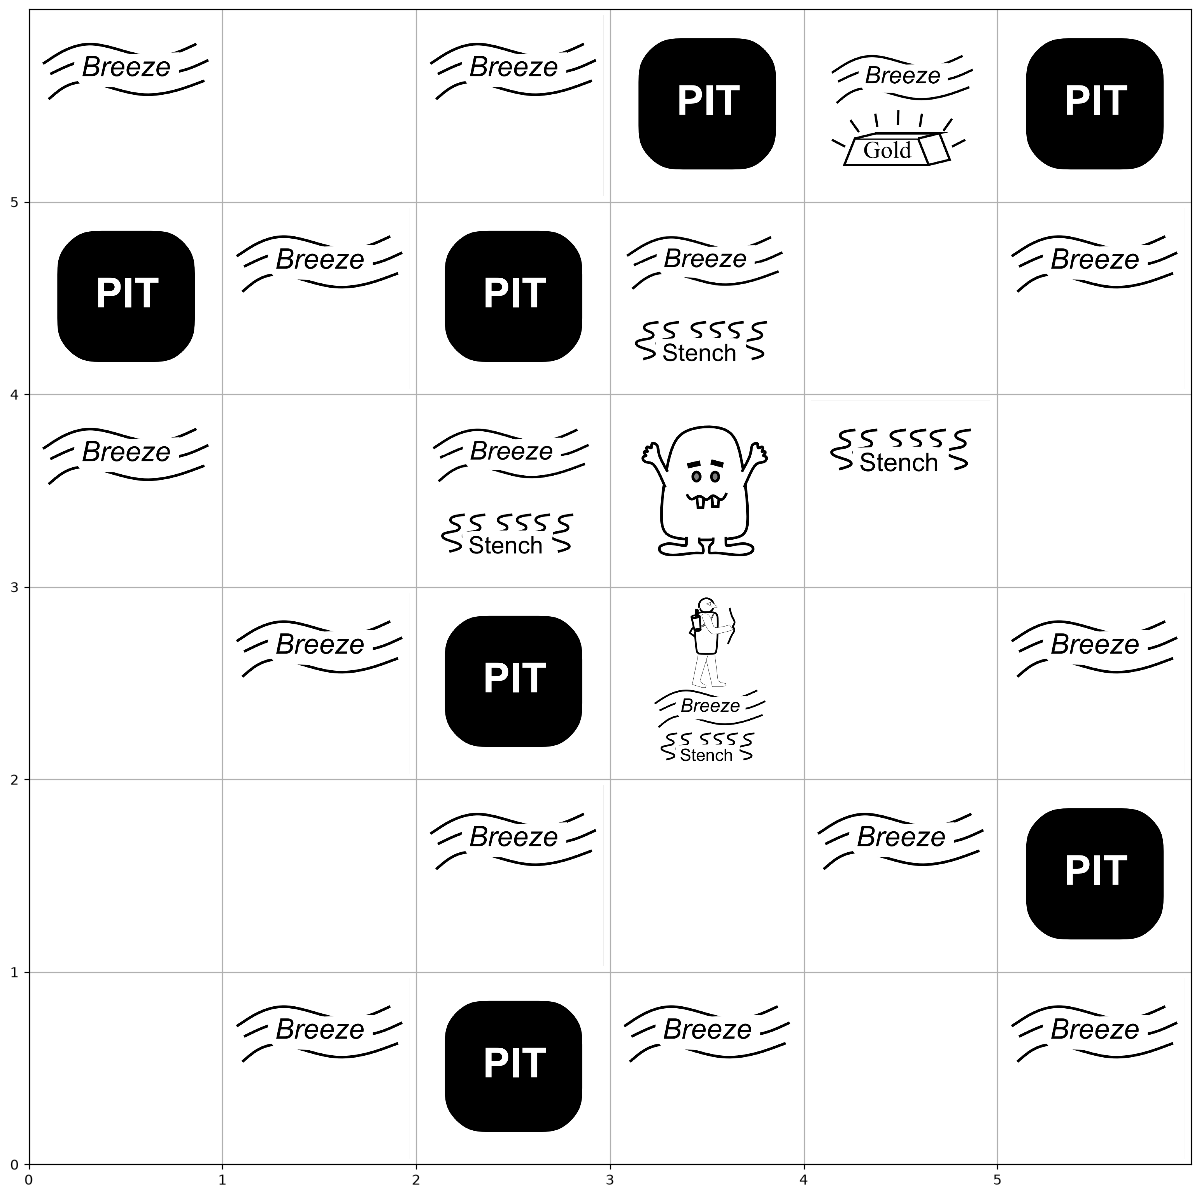

step 6: action=0,
position=[4, 2], rewards=-0.01


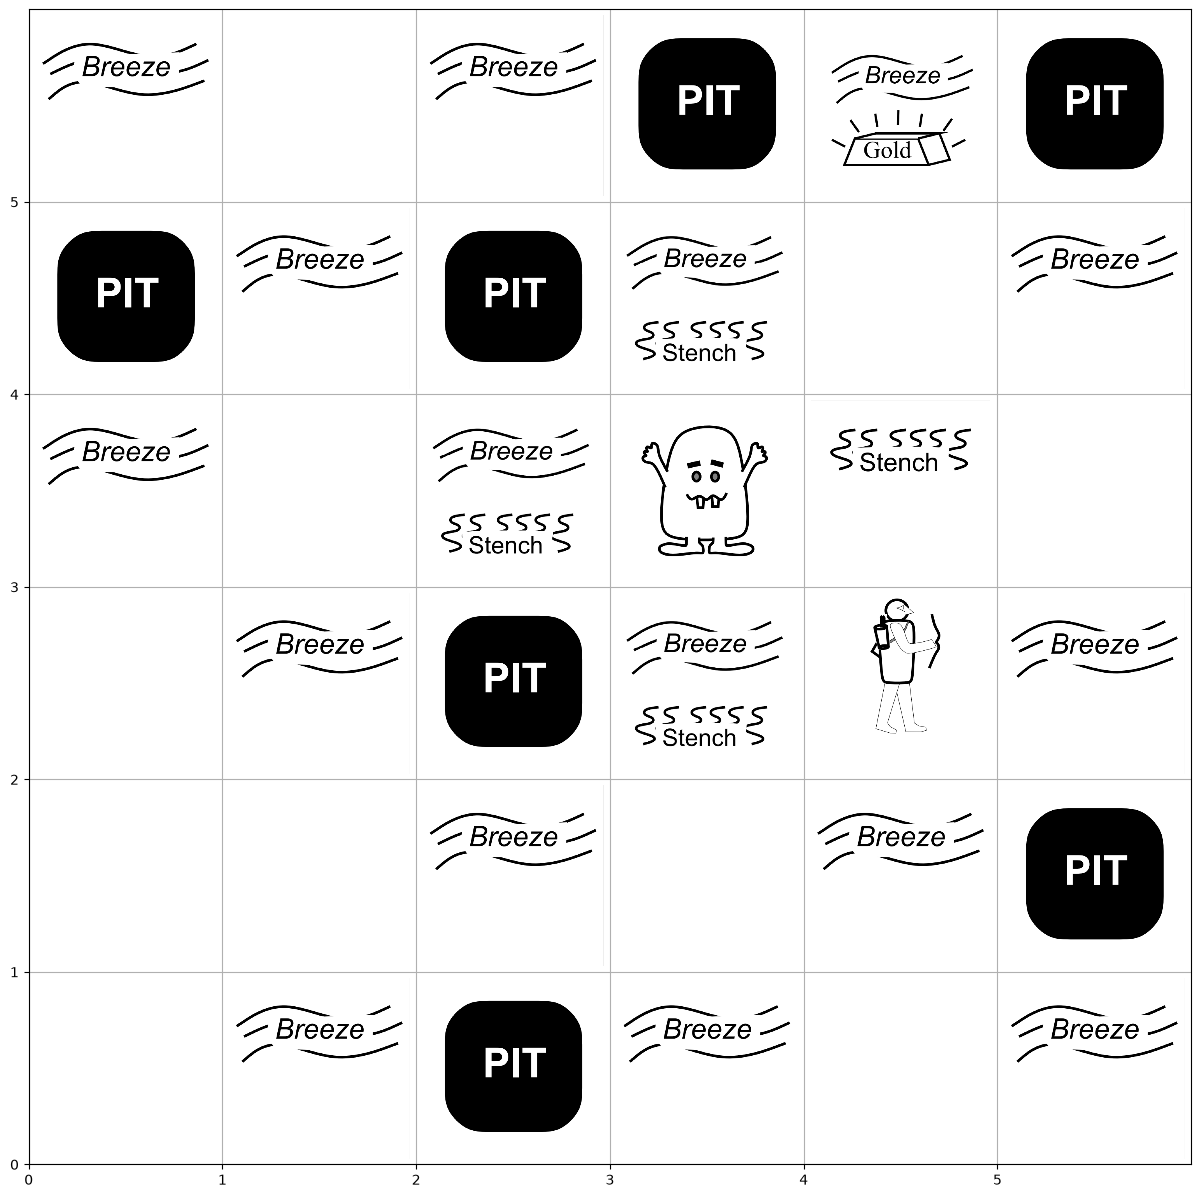

step 7: action=2,
position=[4, 3], rewards=-0.01


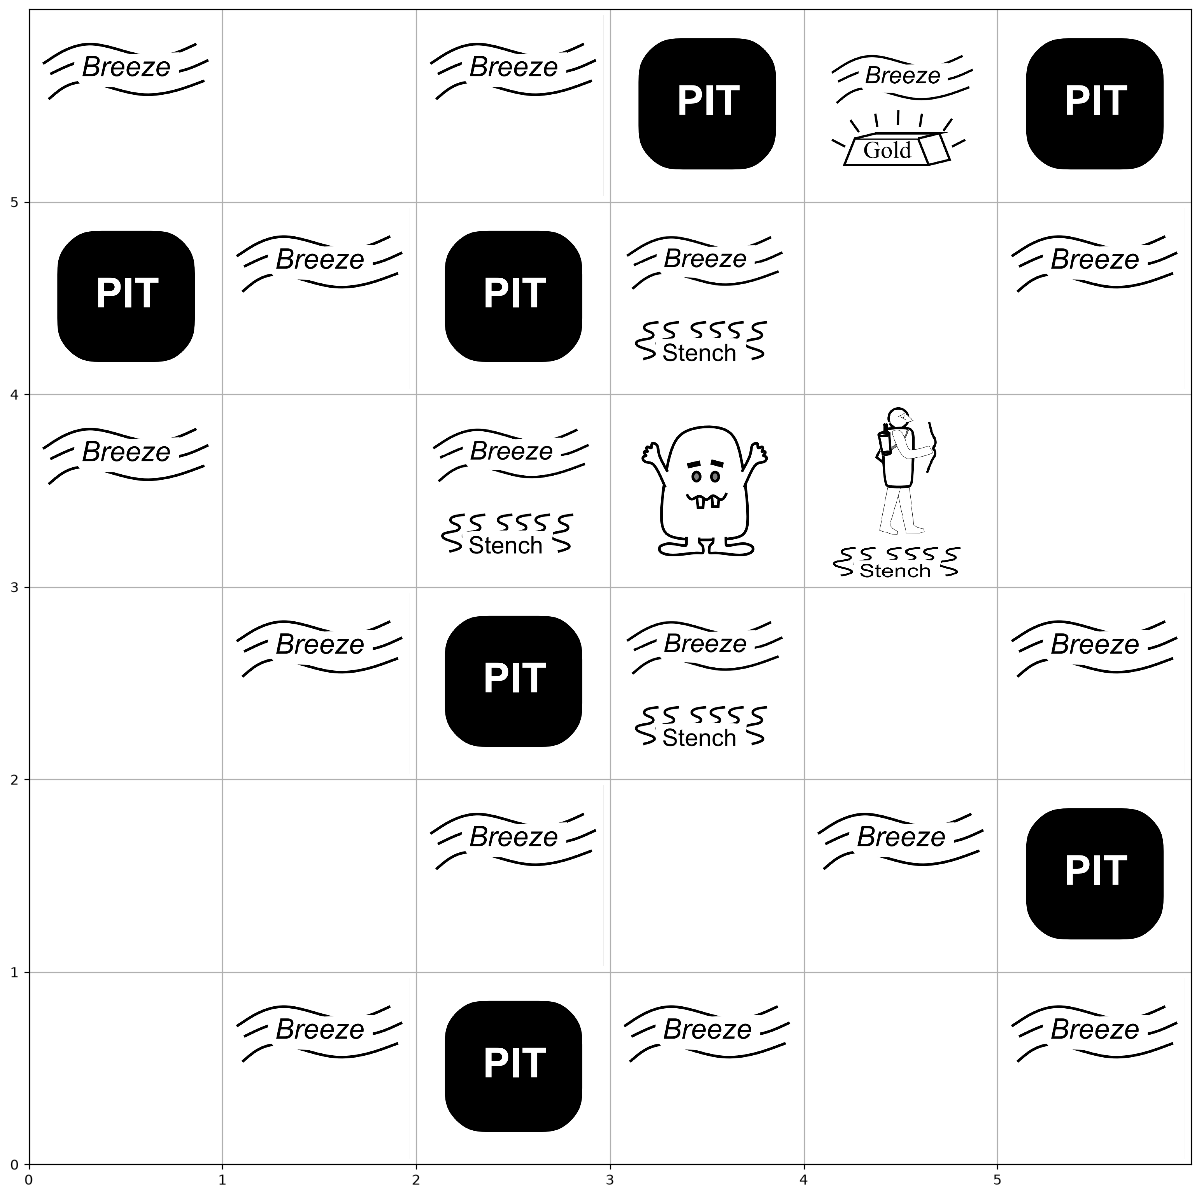

step 8: action=2,
position=[4, 4], rewards=-0.01


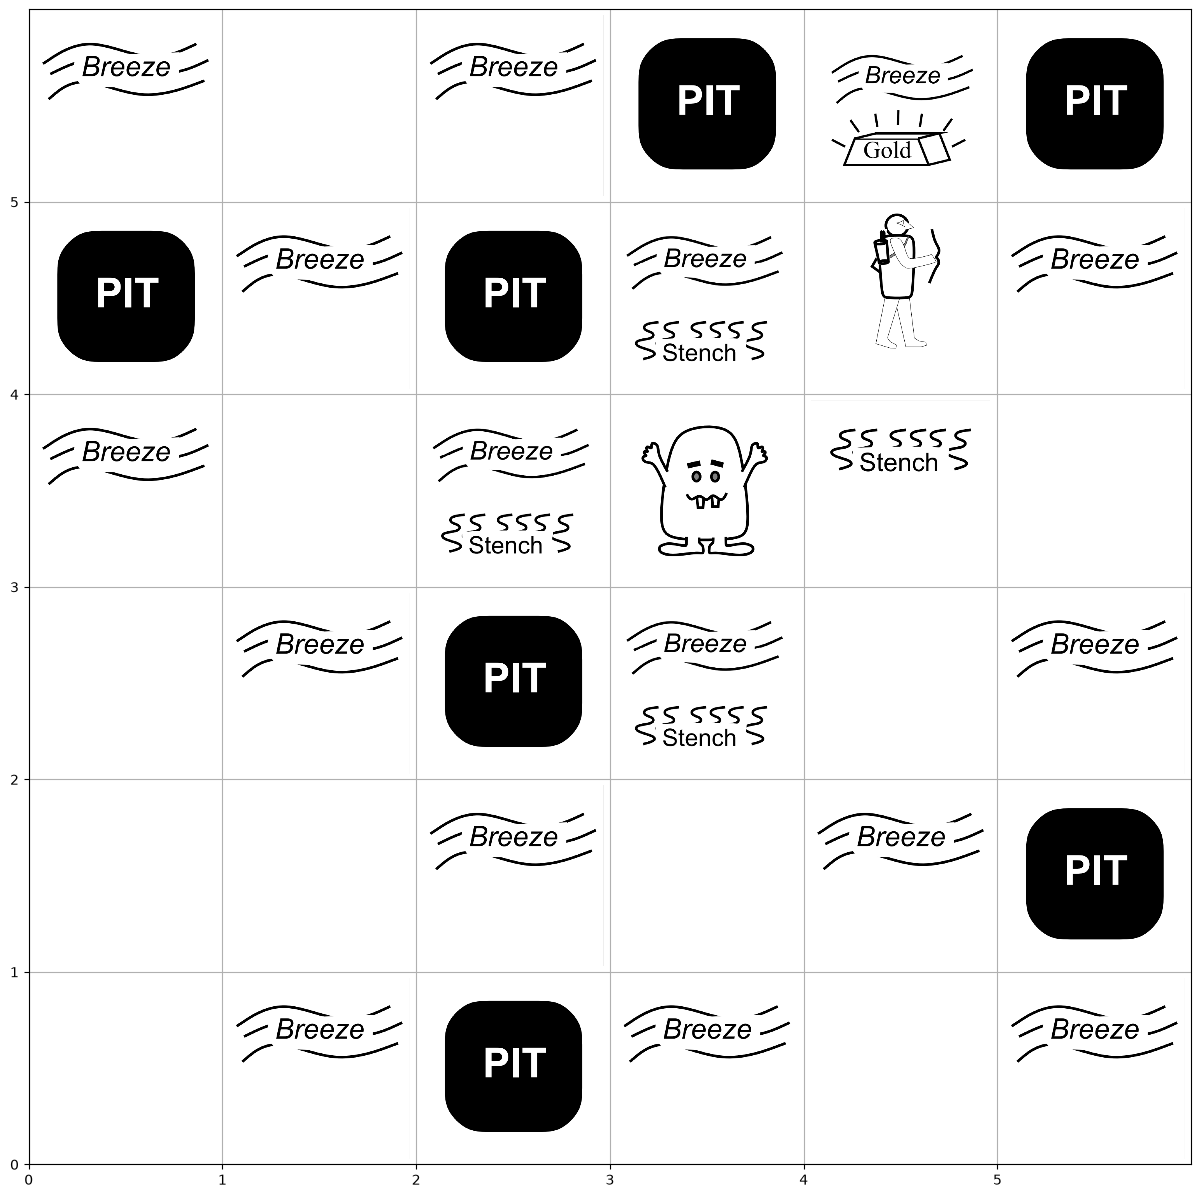

step 9: action=2,
position=[4, 5], rewards=1.0


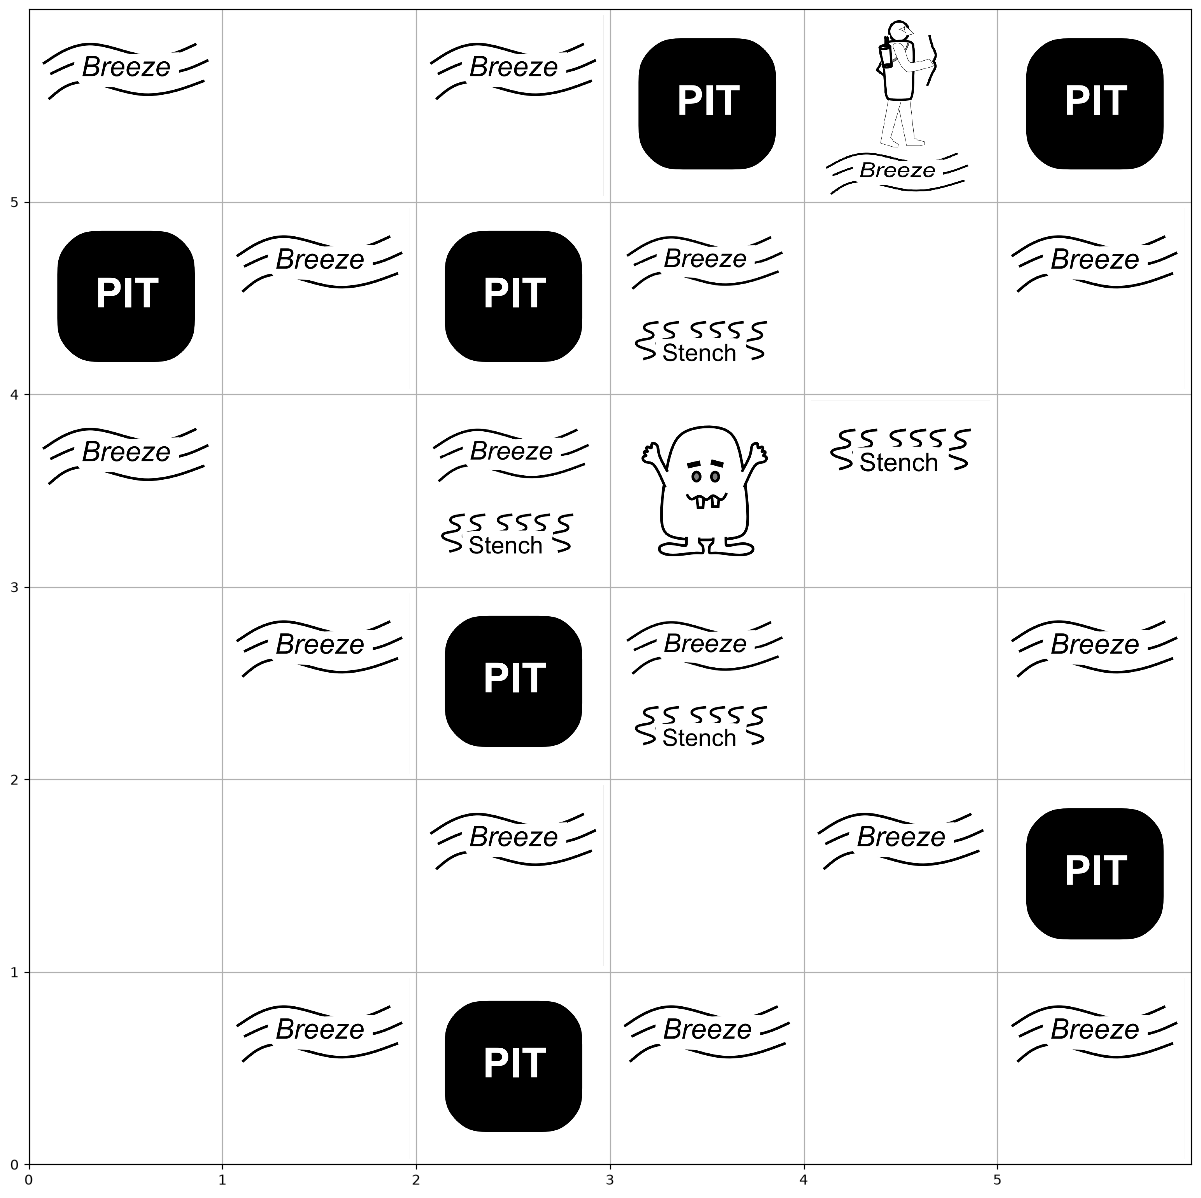

episode ended: collected the gold; steps=9
total reward=0.92


In [13]:
"""Code to render the greedy episode in the grid world environemnt for reporting:
    we put the code in funcitons for easy use and abstraction when applying the DQN to the 2 additional environements

"""
def render_greedy_epsidoes(environment,q_network):
    training = q_network.training
    q_network.eval()

    try:
        state,anything = environment.reset()
        total_reward = 0.0
        steps = 0
        terminated = truncated = False
        print(f"Start: position={environment.agent_pos.tolist()}")
        environment.render(plot=True)
        for t in range(environment.max_timesteps):
            action = greedy_action(state,q_network)
            next_state,reward,terminated,truncated,info = environment.step(action)
            steps+=1
            total_reward+=float(reward)
            state = next_state
            print(f"step {steps}: action={action},")
            print(f"position={environment.agent_pos.tolist()}, rewards={reward}")
            environment.render(plot=True)
            if terminated or truncated:
                break

        if environment.gold_quantity == 0:
            outcome = "collected the gold"
        elif terminated:
            outcome = "termianted without collecitng the gold: s"
        elif truncated:
            outcome = "reached max timesteps"
        else:
            outcome = "reached the step limit"

        print(f"episode ended: {outcome}; steps={steps}")
        print(f"total reward={total_reward:.2f}")
        return {"steps_took": steps, "total_reward": total_reward, "outcome": outcome}
    finally:
        q_network.train(training)

visual_result = render_greedy_epsidoes(environment,online_network)



# Part 2.2 Applying DQN to Cart Pole environment and Lunar Lander

# Cart-Pole DQN: Code mostly stays the same with minor tweaks to the envionment

In [40]:
class Cart_Pole_Q_Network(nn.Module):
    """Edit dqn to use the cartpoles dimensions"""
    def __init__(self):
        super().__init__()
        self.cart_layers = nn.Sequential(
        nn.Linear(4,64),
        nn.ReLU(),
        nn.Linear(64,2)
    )

    #Forward propogation
    def forward(self,state):
        return self.cart_layers(state)
    

In [41]:
def observation_tensor(observation):
    return torch.as_tensor(observation,dtype=torch.float32, device=device).unsqueeze(0)

def pick_action_cart(observation,epsilon,network,env):
    if random.random() < epsilon:
        return env.action_space.sample()
    with torch.no_grad():
        return int(network(observation_tensor(observation)).argmax(dim=1).item())

def train_cart(replay,network,target_network,optimizer,loss_function):
    #Sample a mini_batch and make a gradient descent update
    if len(replay) < BATCH_SIZE:
        return None

    mini_batch = random.sample(replay,BATCH_SIZE)
    states,actions,rewards,next_states,termination = zip(*mini_batch)
    #one-hot encode the states and convert actions,and rweads to tensors
    states = torch.as_tensor(np.stack(states), dtype=torch.float32,device=device)
    actions = torch.as_tensor(actions,dtype=torch.long,device=device).unsqueeze(1)
    rewards = torch.as_tensor(rewards,dtype=torch.float32,device=device)
    next_states = torch.as_tensor(np.stack(next_states), dtype=torch.float32,device=device)
    termination = torch.as_tensor(termination,dtype=torch.float32,device=device)

    #Get the predicted  values from the live Q network. Q_online(s,a)
    predictions = network(states).gather(1,actions).squeeze(1)
    #update the target network
    with torch.no_grad():
        next_q_values = target_network(next_states).max(dim=1).values
        targets = rewards + GAMMA * (1.0 - termination) * next_q_values

    #compute the loss, take rthe gradient and perform grdient descent/backpropagation
    loss = loss_function(predictions,targets)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    return loss.item()



In [ ]:
#Change the enviornemnt to cart_pole
cart_env = gym.make("CartPole")
replay_cart = deque(maxlen=REPLAY_BUFFER_SIZE)
online_cart_network = Cart_Pole_Q_Network().to(device)
target_cart_network = Cart_Pole_Q_Network().to(device)
target_cart_network.load_state_dict(online_cart_network.state_dict())
target_cart_network.eval()
optimizer = torch.optim.Adam(online_cart_network.parameters(),lr=LEARNING_RATE)





/Users/cjb/CSE546/proj2/assignment_2_part_1/.venv/lib/python3.14/site-packages/gymnasium/envs/registration.py:519: UserWarning: WARN: Using the latest versioned environment `CartPole-v1` instead of the unversioned environment `CartPole`.
  logger.warn(


In [63]:
def train_loop(max_episodes,env,max_steps,online_network,target_network,optimizer):
    for episode in range(max_episodes):
        state,info = env.reset()
        cart_rewards = []
        cart_losses = []
        epsilon_hist_cart = []
        training_steps_hist = []
        env_steps = 0

        episode_reward = 0.0
        episode_return = 0.0

        for t in range(max_steps):
            #to slighlt change epislon as training goes on so we are not stuck exploring
            epsilon = EPSILON_END + (EPSILON_START - EPSILON_END) * (max(0, EPSILON_DECAY_STEPS - env_steps) / EPSILON_DECAY_STEPS)
            training_steps_hist.append(env_steps)
            epsilon_hist_cart.append(epsilon)
            action = pick_action_cart(state,epsilon,online_network,env=env)
            next_state,reward,terminated,truncated,info = env.step(action)
            done = terminated or truncated
            replay_cart.append((np.asarray(state,dtype=np.float32).copy(),action,float(reward),np.asarray(next_state,dtype=np.float32).copy(),terminated))
            loss = train_cart(replay_cart,online_network,target_network,optimizer,loss_function)
            if loss is not None:
                cart_losses.append(loss)

            
            if env_steps % TARGET_UPDATE == 0:
                target_network.load_state_dict(online_network.state_dict())

    
            state = next_state
            episode_return += float(reward)
            env_steps+=1


            #if we have terminated/ hit the the terminated state we are done
            if terminated or truncated:
                break

            cart_rewards.append(episode_return)
            cart_losses.append(float(np.mean(cart_losses)) if cart_losses else np.nan)
    return cart_rewards,cart_losses,epsilon_hist_cart,training_steps_hist
    

In [65]:
cart_rewards,cart_losses,epsilon_cart_hist,training_steps_returned = train_loop(MAX_EPISODES,cart_env,max_steps=100,online_network=online_cart_network,target_network=target_cart_network,optimizer=optimizer)
cart_env.close()


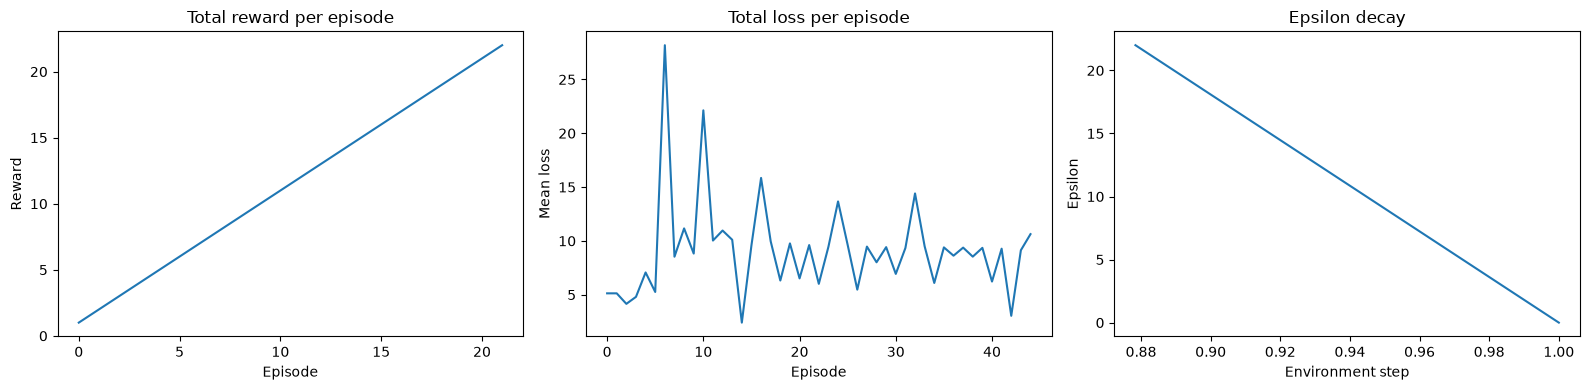

In [ ]:
plot_rewards(cart_rewards,cart_losses,epsilon_cart_hist,training_steps_returned)
#100 max steps

In [71]:
def plot_eval_greedy_cart(network,episodes=10,render=False,plot=True):
    """Same code as grid world q_netowrk applied to """
    render_mode = "human" if render else None
    cart_eavl_env = gym.make("CartPole",render_mode=render_mode)
    cart_ep_rewards = []
    cart_training = network.training
    network.eval()
    try:
        for episode in range(episodes):
            cart_state,anything = cart_eavl_env.reset()
            total_cart_reward = 0.0
            for step in range(MAX_STEPS):
                with torch.no_grad():
                    cart_action = int(network(observation_tensor(cart_state)).argmax(dim=1).item())

                    cart_state, cart_rewards, terminated, truncated, info = cart_eavl_env.step(cart_action)
                    total_cart_reward+=float(cart_rewards)
                    if render:
                        cart_eavl_env.render()

                    if terminated or truncated:
                        break

            cart_ep_rewards.append(total_cart_reward)
            print(f"Episode {episode + 1}: reward = {total_cart_reward:.0f}")
    finally:
        network.train(cart_training)
        cart_eavl_env.close()


    if plot:
        plt.figure(figsize=(10,4))
        plt.plot(range(1,episodes+1), cart_ep_rewards, marker='o')
        plt.xlabel("Episode")
        plt.ylabel("Total reward")
        plt.title("Cartpole Greedy evaluation rewards")
        plt.grid(True)
        plt.show()

    return cart_ep_rewards



            

/Users/cjb/CSE546/proj2/assignment_2_part_1/.venv/lib/python3.14/site-packages/gymnasium/envs/registration.py:519: UserWarning: WARN: Using the latest versioned environment `CartPole-v1` instead of the unversioned environment `CartPole`.
  logger.warn(


Episode 1: reward = 100
Episode 2: reward = 100
Episode 3: reward = 100
Episode 4: reward = 100
Episode 5: reward = 100
Episode 6: reward = 100
Episode 7: reward = 100
Episode 8: reward = 100
Episode 9: reward = 100
Episode 10: reward = 100


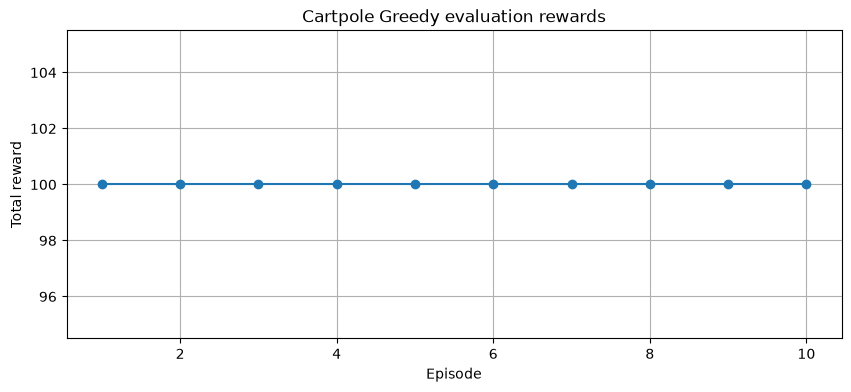

[100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0]

In [72]:
#Evaluate greedy rewrads plots
cart_evaluation_rewards = plot_eval_greedy_cart(online_cart_network,episodes=10)
cart_evaluation_rewards

In [76]:
#render cart environemnt
cart_render = plot_eval_greedy_cart(online_cart_network,episodes=1,render=True)
cart_render

/Users/cjb/CSE546/proj2/assignment_2_part_1/.venv/lib/python3.14/site-packages/gymnasium/envs/registration.py:519: UserWarning: WARN: Using the latest versioned environment `CartPole-v1` instead of the unversioned environment `CartPole`.
  logger.warn(


DependencyNotInstalled: pygame is not installed, run `pip install "gymnasium[classic-control]"`